In [1]:
# For calculating acceleration and angular velocity biases for the IMU
# We're currently not using these functions

import numpy as np

def angular_velocity_bias(dt, prev_bias):
    """
    Compute the total angular velocity bias for all three axes for an ADIS16485 IMU,
    including a Gauss–Markov dynamic bias update and a random-walk noise (ARW) term."""
    
    arw = np.radians(np.array([0.3, 0.3, 0.3]) / 60.0)
    # Static gyro bias: 0.2 deg/s converted to rad/s.
    gb_fix = np.radians(np.array([0.2, 0.2, 0.2]))
    # Dynamic drift: 6.25/3600 deg/s converted to rad/s.
    gb_drift = np.radians(np.array([6.25/3600, 6.25/3600, 6.25/3600]))
    # Correlation time (seconds), assumed constant.
    corr_time = np.array([100, 100, 100])
    
    beta = dt / corr_time
    a1 = np.exp(-beta)
    a2 = gb_drift * np.sqrt(1 - np.exp(-2 * beta))
    new_dynamic_bias = a1 * prev_bias + a2 * np.random.normal(0, 1, 3)
    # ARW noise contribution: scales as 1/sqrt(dt)
    arw_noise = arw / np.sqrt(dt)
    total_bias = gb_fix + new_dynamic_bias + arw_noise
    return total_bias

def acceleration_bias(dt, prev_bias):
    """
    Compute the total linear acceleration bias for all three axes for an ADIS16485 IMU,
    including a Gauss–Markov dynamic bias update and a random-walk noise (VRW) term.
    
    Args:
      dt (float): Time step in seconds.
      
    Returns:
      np.array: A 3-element vector (m/s²) representing the total accelerometer bias.
    """
    # VRW: convert 0.023 m/s/root-hour to m/s²/√Hz.
    vrw = np.array([0.023, 0.023, 0.023]) / 60.0
    # Static accelerometer bias: 3 mg converted to m/s².
    ab_fix = np.array([3, 3, 3]) * 0.001 * 9.81
    # Dynamic drift: 0.032 mg converted to m/s².
    ab_drift = np.array([0.032, 0.032, 0.032]) * 0.001 * 9.81
    corr_time = np.array([100, 100, 100])
    
    beta = dt / corr_time
    a1 = np.exp(-beta)
    a2 = ab_drift * np.sqrt(1 - np.exp(-2 * beta))
    new_dynamic_bias = a1 * prev_bias + a2 * np.random.normal(0, 1, 3)
    vrw_noise = vrw / np.sqrt(dt)
    total_bias = ab_fix + new_dynamic_bias + vrw_noise
    return total_bias



In [1]:
# To filter out the outliers
def low_pass_filter(data, threshold):
    for ch in range(data.shape[0]):
        for i in range(1, data.shape[1]):
            if abs(data[ch, i]) > threshold:
                data[ch, i] = data[ch, i-1]
    return data

In [2]:
import numpy as np

def exp_moving_average(data, alpha):

#Applies an exponentially decaying moving average filter to a 1D NumPy array.

    if len(data) == 0:
        return data

    smoothed = np.empty_like(data, dtype=float)
    smoothed[0] = data[0]  # Initialize with the first data point.
    for i in range(1, len(data)):
        smoothed[i] = alpha * data[i] + (1 - alpha) * smoothed[i-1]
    return smoothed

# For multidimensional data
def exp_mov_ave_2d(data, alpha):
   # Apply the 1D filter to each row.
    smoothed = np.array([exp_moving_average(channel, alpha) for channel in data])
    return smoothed


In [3]:
def integrate_dynamic_model(vx, vx_vicon, vy, vy_vicon, dt, params, heading_array, initial_pos_x, initial_pos_y):
    """
    Full dynamic model with traction and rolling resistance, with proper coordinate transforms
    and position initialization
    """
    # Unpack parameters
    m, N, C1, At, C2, R1, A_roll, R2 = params
    
    # Create arrays for storing results
    n = len(vx)
    vel_dyn_x = np.zeros_like(vx)
    pos_dyn_x = np.zeros_like(vx)
    vel_dyn_y = np.zeros_like(vy)
    pos_dyn_y = np.zeros_like(vy)
    
    # Properly initialize with Vicon data
    vel_dyn_x[0] = vx_vicon[0]
    vel_dyn_y[0] = vy_vicon[0]
    pos_dyn_x[0] = initial_pos_x
    pos_dyn_y[0] = initial_pos_y
    
    # Avoid extreme parameter values
    At = min(At, 10.0)
    A_roll = min(A_roll, 10.0)
    
    for i in range(1, len(vx)):
        # Current heading angle
        heading = heading_array[i-1]
        
        # Current velocities (with safety limits)
        curr_vx = np.clip(vel_dyn_x[i-1], -10.0, 10.0)
        curr_vy = np.clip(vel_dyn_y[i-1], -10.0, 10.0)
        
        # Transform to vehicle coordinates
        v_long = curr_vx * np.cos(heading) + curr_vy * np.sin(heading)
        v_lat = -curr_vx * np.sin(heading) + curr_vy * np.cos(heading)
        
        # Ground truth velocities in vehicle coordinates
        v_long_vicon = vx_vicon[i-1] * np.cos(heading) + vy_vicon[i-1] * np.sin(heading)
        v_lat_vicon = -vx_vicon[i-1] * np.sin(heading) + vy_vicon[i-1] * np.cos(heading)
        
        # Relative velocities
        v_rel_long = v_long - v_long_vicon
        v_rel_lat = v_lat - v_lat_vicon
        
        # Safely calculate longitudinal forces
        try:
            # Safe exponential calculations
            exp_term_long = np.exp(-At * np.clip(np.abs(v_rel_long), 0, 5))
            roll_exp_long = np.exp(-A_roll * np.clip(np.abs(v_long), 0, 5))
            
            # Traction force
            f_traction_long = N * (np.sign(v_rel_long) * C1 * (1 - exp_term_long) + C2 * v_rel_long)
            # Rolling resistance
            f_roll_long = -np.sign(v_long) * N * (R1 * (1 - roll_exp_long) + R2 * np.abs(v_long))
            # Total force
            F_long = 2 * f_traction_long + 4 * f_roll_long
        except:
            # Fallback to simple damping if calculation fails
            F_long = -10.0 * v_rel_long
        
        # Safely calculate lateral forces
        try:
            # Safe exponential calculations
            exp_term_lat = np.exp(-At * np.clip(np.abs(v_rel_lat), 0, 5))
            roll_exp_lat = np.exp(-A_roll * np.clip(np.abs(v_lat), 0, 5))
            
            # Traction force
            f_traction_lat = N * (np.sign(v_rel_lat) * C1 * (1 - exp_term_lat) + C2 * v_rel_lat)
            # Rolling resistance
            f_roll_lat = -np.sign(v_lat) * N * (R1 * (1 - roll_exp_lat) + R2 * np.abs(v_lat))
            # Total force
            F_lat = 2 * f_traction_lat + 4 * f_roll_lat
        except:
            # Fallback to simple damping if calculation fails
            F_lat = -10.0 * v_rel_lat
        
        # Calculate accelerations (with safety limits)
        acc_long = np.clip(F_long / m, -10.0, 10.0)
        acc_lat = np.clip(F_lat / m, -10.0, 10.0)
        
        # Transform accelerations back to world coordinates
        acc_x = acc_long * np.cos(heading) - acc_lat * np.sin(heading)
        acc_y = acc_long * np.sin(heading) + acc_lat * np.cos(heading)
        
        # Update velocities
        vel_dyn_x[i] = curr_vx + acc_x * dt[i-1]
        vel_dyn_y[i] = curr_vy + acc_y * dt[i-1]
        
        # Update positions with trapezoidal rule
        pos_dyn_x[i] = pos_dyn_x[i-1] + (curr_vx + vel_dyn_x[i]) * 0.5 * dt[i-1]
        pos_dyn_y[i] = pos_dyn_y[i-1] + (curr_vy + vel_dyn_y[i]) * 0.5 * dt[i-1]
    
    return vel_dyn_x, pos_dyn_x, vel_dyn_y, pos_dyn_y

def model_error(params, vx, vx_vicon, vy, vy_vicon, dt, gt_vel_x, gt_vel_y, gt_pos_x, gt_pos_y, heading_array):
    """Error function for the full dynamic model with proper initialization"""
    try:
        # Fix m and N to reasonable values
        if len(params) == 6:
            C1, At, C2, R1, A_roll, R2 = params
            m = 15.0
            N = 36.8
        else:
            m, N, C1, At, C2, R1, A_roll, R2 = params
        
        # Create full parameter set
        full_params = np.array([m, N, C1, At, C2, R1, A_roll, R2])
        
        # Initialize with ground truth positions
        initial_pos_x = gt_pos_x[0]
        initial_pos_y = gt_pos_y[0]
        
        # Get model predictions
        vel_dyn_x, pos_dyn_x, vel_dyn_y, pos_dyn_y = integrate_dynamic_model(
            vx, vx_vicon, vy, vy_vicon, dt, full_params, heading_array,
            initial_pos_x, initial_pos_y
        )
        
        # Check for invalid values
        if (np.isnan(vel_dyn_x).any() or np.isnan(pos_dyn_x).any() or 
            np.isnan(vel_dyn_y).any() or np.isnan(pos_dyn_y).any()):
            return np.ones(len(vx) * 4) * 1e3
        
        # Calculate errors
        vel_error_x = vel_dyn_x - gt_vel_x
        pos_error_x = pos_dyn_x - gt_pos_x
        vel_error_y = vel_dyn_y - gt_vel_y  
        pos_error_y = pos_dyn_y - gt_pos_y
        
        # Clip extreme error values to prevent overflow
        vel_error_x = np.clip(vel_error_x, -10, 10)
        pos_error_x = np.clip(pos_error_x, -10, 10)
        vel_error_y = np.clip(vel_error_y, -10, 10)
        pos_error_y = np.clip(pos_error_y, -10, 10)
        
        # Weighted error with emphasis on position
        return np.concatenate([
            0.3 * vel_error_x, 0.7 * pos_error_x,
            0.3 * vel_error_y, 0.7 * pos_error_y
        ])
    except Exception as e:
        print(f"Error in model_error: {e}")
        return np.ones(len(vx) * 4) * 1e3

# def gradient_descent(x0, vx, vx_vicon, vy, vy_vicon, dt, gt_vel_x, gt_vel_y, gt_pos_x, gt_pos_y, heading_array,
#                      lr=5e-5, max_iter=500, tol=1e-6):
#     """Gradient descent with numerical stability enhancements"""
#     x = x0.copy()
#     best_x = x.copy()
#     best_cost = float('inf')
#     costs = []
    
#     # Parameter bounds
#     lower_bounds = np.array([0.001, 0.01, 0.001, 0.001, 0.01, 0.001])
#     upper_bounds = np.array([0.5, 5.0, 0.1, 0.5, 5.0, 0.1])
    
#     # Ensure initial parameters are within bounds
#     x = np.maximum(np.minimum(x, upper_bounds), lower_bounds)
    
#     for i in range(max_iter):
#         # Current cost
#         error = model_error(x, vx, vx_vicon, vy, vy_vicon, dt, gt_vel_x, gt_vel_y, gt_pos_x, gt_pos_y, heading_array)
#         cost = np.mean(np.square(error))  # Use mean instead of sum for better scaling
#         costs.append(cost)
        
#         # Track best parameters
#         if cost < best_cost:
#             best_cost = cost
#             best_x = x.copy()
#             print(f"New best at iteration {i}: Cost = {cost}, Params = {x}")
        
#         # Print progress
#         if i % 20 == 0:
#             print(f"Iteration {i}: Cost = {cost}, Params = {x}")
        
#         # Numerical gradient
#         grad = np.zeros_like(x)
#         eps = 1e-5
#         for j in range(len(x)):
#             x_eps = x.copy()
#             x_eps[j] += eps
            
#             # Ensure perturbed parameter is within bounds
#             x_eps = np.maximum(np.minimum(x_eps, upper_bounds), lower_bounds)
            
#             error_eps = model_error(x_eps, vx, vx_vicon, vy, vy_vicon, dt, gt_vel_x, gt_vel_y, gt_pos_x, gt_pos_y, heading_array)
#             cost_eps = np.mean(np.square(error_eps))
            
#             # Compute gradient safely
#             grad[j] = (cost_eps - cost) / (x_eps[j] - x[j] if x_eps[j] != x[j] else eps)
        
#         # Clip extreme gradient values
#         grad = np.clip(grad, -1e3, 1e3)
        
#         # Update step with small learning rate
#         x_new = x - lr * grad
        
#         # Ensure parameters stay within bounds
#         x_new = np.maximum(np.minimum(x_new, upper_bounds), lower_bounds)
        
#         # Check convergence
#         if i > 100 and np.linalg.norm(x_new - x) < tol:
#             print(f"Converged after {i} iterations")
#             break
        
#         x = x_new
    
#     # Return the best parameters found
#     return best_x, costs

# def estimate_dynamic_parameters(self, dt, vx, vx_vicon, vy, vy_vicon, xs, ys, gt_pos_x, gt_pos_y):
#     """Estimate dynamic parameters using the full model with proper initialization"""
#     # Fixed physical parameters
#     m = 15.0
#     N = 36.8
    
#     # Initial conservative guess for friction parameters
#     x0 = np.array([0.01, 0.1, 0.005, 0.01, 0.1, 0.005])  # [C1, At, C2, R1, A_roll, R2]
    
#     # Run optimization
#     optimized_params, cost_history = gradient_descent(
#         x0=x0, 
#         vx=vx, vx_vicon=vx_vicon, 
#         vy=vy, vy_vicon=vy_vicon, 
#         dt=dt,
#         gt_vel_x=vx_vicon, gt_vel_y=vy_vicon,
#         gt_pos_x=gt_pos_x, gt_pos_y=gt_pos_y,
#         heading_array=self.heading_array,
#         lr=5e-3, 
#         max_iter=500, 
#         tol=1e-6
#     )
    
#     # Store parameters
#     self.friction_params = optimized_params
#     self.dynamic_params = np.array([m, N, *optimized_params])
    
#     # Integrate model with optimized parameters and correct initialization
#     vel_dyn_x, pos_dyn_x, vel_dyn_y, pos_dyn_y = integrate_dynamic_model(
#         vx, vx_vicon, vy, vy_vicon, dt, 
#         self.dynamic_params,
#         self.heading_array,
#         gt_pos_x[0], gt_pos_y[0]  # Initialize with ground truth position
#     )
    
#     # Store model results for plotting
#     self.dynamic_model_vel_x = vel_dyn_x
#     self.dynamic_model_vel_y = vel_dyn_y
#     self.dynamic_model_pos_x = pos_dyn_x
#     self.dynamic_model_pos_y = pos_dyn_y
    
#     # Plot cost history
#     plt.figure()
#     plt.plot(cost_history)
#     plt.xlabel('Iteration')
#     plt.ylabel('Cost')
#     plt.title('Optimization Cost History')
#     plt.yscale('log')
#     plt.grid(True)
#     plt.savefig("optimization_cost.png")
#     plt.show()
    
#     print("Optimized friction parameters:", self.friction_params)
#     print("Parameter meanings: [C1, At, C2, R1, A_roll, R2]")
#     print("Full parameter set:", self.dynamic_params)
#     print("Parameter meanings: [m, N, C1, At, C2, R1, A_roll, R2]")
    
#     return self.dynamic_params

def levenberg_marquardt(x0, model_error_func, args,
                        max_iter=100, tol=1e-6, lambda_init=1e-3):
    """
    Levenberg-Marquardt optimization to minimize squared error with parameter bounds.

    Args:
        x0: Initial guess (1D np.array)
        model_error_func: Function that returns residuals (not squared)
        args: Extra arguments passed to model_error_func
        max_iter: Max iterations
        tol: Tolerance for convergence
        lambda_init: Initial damping parameter

    Returns:
        x_opt: Optimized parameters
        cost_history: List of costs over iterations
    """
    import numpy as np

    x = x0.copy()
    lamb = lambda_init
    cost_history = []
    eps = 1e-5

    # Updated bounds based on traction and rolling resistance figures:
    # C1 > 0, At > 0, C2 can be positive or negative, R1 > 0, A_roll > 0, R2 > 0
    lower_bounds = np.array([0.05, 0.1, -0.2, 0.05, 0.1, 0.005])
    upper_bounds = np.array([0.6, 1.0, 0.2, 0.15, 1.0, 0.03])

    for it in range(max_iter):
        r = model_error_func(x, *args)
        cost = np.mean(r**2)
        cost_history.append(cost)

        # Compute numerical Jacobian J (M x N)
        J = np.zeros((len(r), len(x)))
        for i in range(len(x)):
            x_eps = x.copy()
            x_eps[i] += eps
            r_eps = model_error_func(x_eps, *args)
            J[:, i] = (r_eps - r) / eps

        # LM update step
        JTJ = J.T @ J
        JTr = J.T @ r
        H = JTJ + lamb * np.eye(len(x))  # Damped
        dx = -np.linalg.solve(H, JTr)

        x_new = x + dx

        # Enforce parameter bounds
        x_new = np.clip(x_new, lower_bounds, upper_bounds)

        r_new = model_error_func(x_new, *args)
        cost_new = np.mean(r_new**2)

        if cost_new < cost:  # Accept step
            x = x_new
            lamb *= 0.7
        else:  # Reject step, increase damping
            lamb *= 2.0

        if np.linalg.norm(dx) < tol:
            print(f"Converged after {it} iterations.")
            break

        if it % 10 == 0:
            print(f"Iter {it}, Cost = {cost}, λ = {lamb}")

    return x, cost_history

def estimate_dynamic_parameters(self, dt, vx, vx_vicon, vy, vy_vicon, xs, ys, gt_pos_x, gt_pos_y):
    """
    Estimate dynamic parameters using Levenberg-Marquardt optimization.
    """
    import numpy as np

    # Updated initial guess: [C1, At, C2, R1, A_roll, R2]
    x0 = np.array([0.1, 0.3, 0.0, 0.1, 0.3, 0.01])

    # Prepare arguments for model_error
    args = (vx, vx_vicon, vy, vy_vicon, dt, vx_vicon, vy_vicon, gt_pos_x, gt_pos_y, self.heading_array)

    # Run optimizer
    optimized_params, cost_history = levenberg_marquardt(
        x0=x0,
        model_error_func=model_error,
        args=args,
        max_iter=200,
        tol=1e-6
    )

    # Fixed physical parameters
    m = 15.0
    N = 36.8

    # Store parameters
    self.friction_params = optimized_params
    self.dynamic_params = np.array([m, N, *optimized_params])

    # Integrate model with optimized parameters
    vel_dyn_x, pos_dyn_x, vel_dyn_y, pos_dyn_y = integrate_dynamic_model(
        vx, vx_vicon, vy, vy_vicon, dt, 
        self.dynamic_params, self.heading_array,
        gt_pos_x[0], gt_pos_y[0]
    )

    # Store model results for plotting
    self.dynamic_model_vel_x = vel_dyn_x
    self.dynamic_model_vel_y = vel_dyn_y
    self.dynamic_model_pos_x = pos_dyn_x
    self.dynamic_model_pos_y = pos_dyn_y

    # Optionally: plot cost history
    import matplotlib.pyplot as plt
    plt.figure()
    plt.plot(cost_history)
    plt.xlabel('Iteration')
    plt.ylabel('Cost')
    plt.title('Levenberg-Marquardt Optimization Cost History')
    plt.yscale('log')
    plt.grid(True)
    plt.savefig("optimization_cost_lm.png")
    plt.show()

    print("Optimized friction parameters:", self.friction_params)
    print("Full parameter set:", self.dynamic_params)

    return self.dynamic_params



/home/devuser/retail-bot/.venv/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


Downsampled Vicon timestamps (first 5): [0.00000000e+00 3.05175781e-05 9.98210907e-03 1.00085735e-02
 1.99759007e-02]
Downsampled Vicon poses (first 5): [[ 6.55920941e+00  6.55920589e+00  6.55922393e+00  6.55921670e+00
   6.55920846e+00]
 [-1.46632212e-01 -1.46638861e-01 -1.46613857e-01 -1.46621417e-01
  -1.46643672e-01]
 [ 9.55890732e-02  9.55912600e-02  9.55686579e-02  9.56103074e-02
   9.55854265e-02]
 [ 9.98182468e-01  9.98185045e-01  9.98187526e-01  9.98186989e-01
   9.98186960e-01]
 [-1.58792774e-02 -1.58097943e-02 -1.57891006e-02 -1.56494229e-02
  -1.56657835e-02]
 [-4.16660993e-03 -4.15640234e-03 -4.15418842e-03 -4.10065943e-03
  -4.10320181e-03]
 [ 5.79848915e-02  5.79602561e-02  5.79233050e-02  5.79742543e-02
   5.79701651e-02]]
IMU: Initial time set at idx 0
IMU timestamp: 0.0
IMU timestamp: 0.008074522018432617
IMU timestamp: 0.015958309173583984
IMU timestamp: 0.023865938186645508
IMU timestamp: 0.0318598747253418
Initialized state at timestep 0 with Vicon pose
Optimizing 

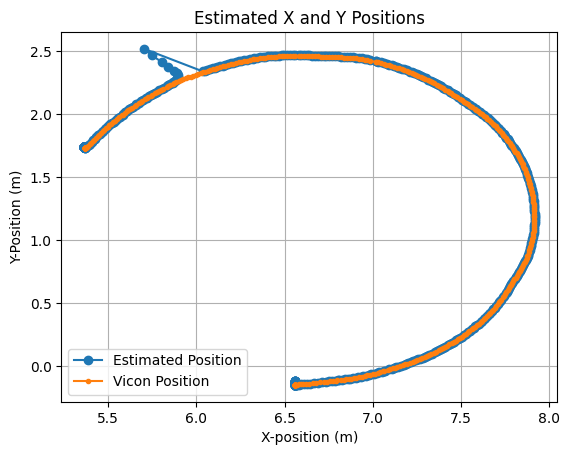

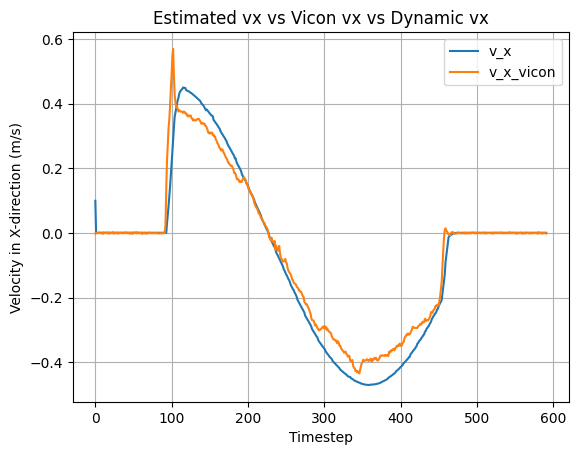

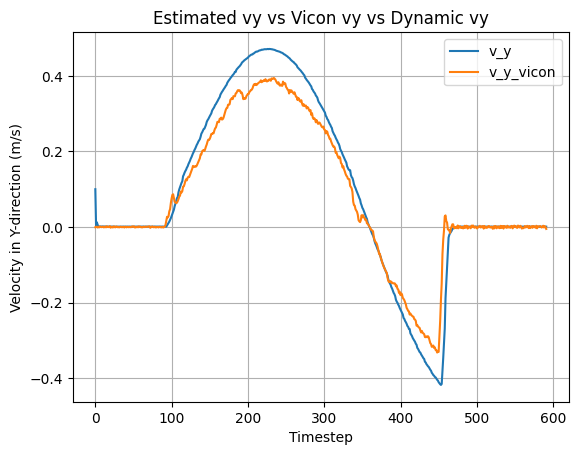

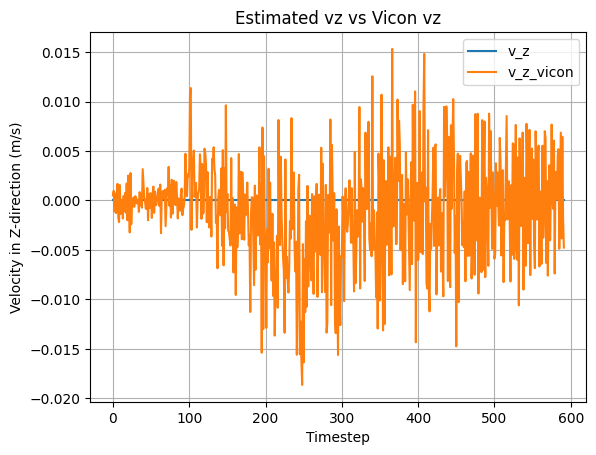

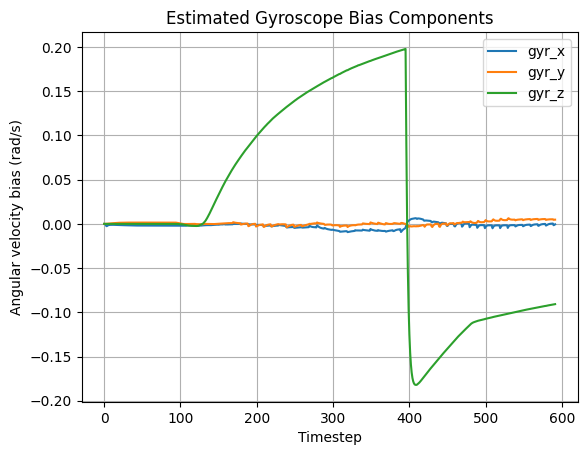

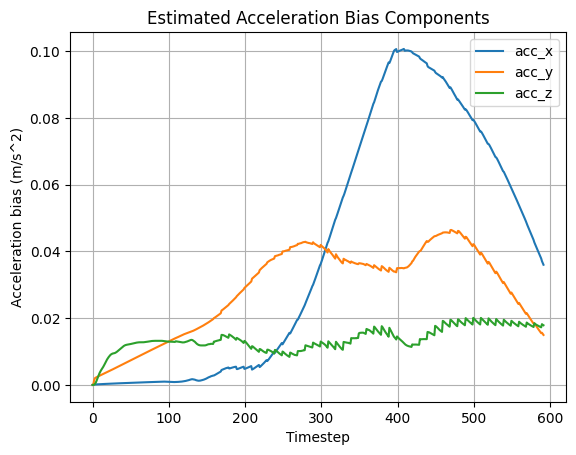

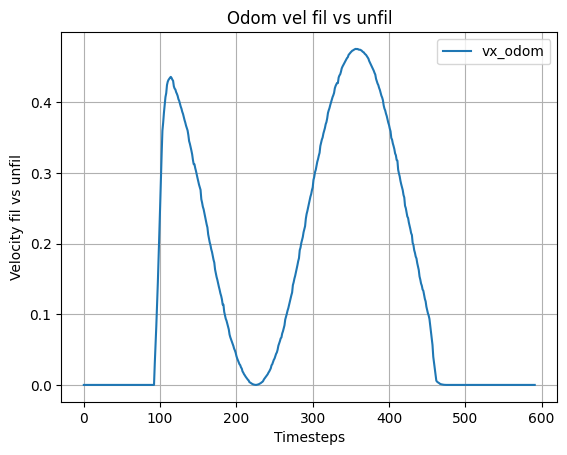

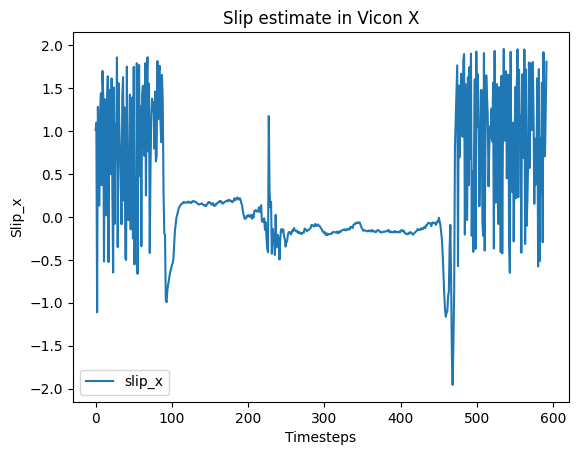

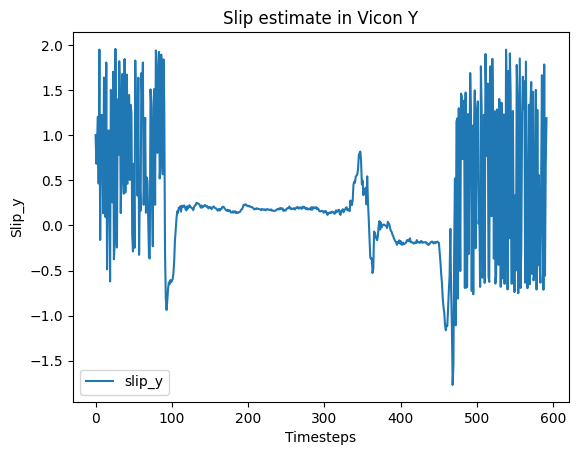

Iter 0, Cost = 0.8342839575469325, λ = 0.002
Iter 10, Cost = 0.0886975231076561, λ = 0.25088
Iter 20, Cost = 0.08823103377985705, λ = 31.470387199999998
Iter 30, Cost = 0.05679580214382243, λ = 169.25529525452797
Iter 40, Cost = 0.051803010641527245, λ = 111.51121089583974
Iter 50, Cost = 0.049798381225110454, λ = 209.90691921095433
Iter 60, Cost = 0.04563904768764402, λ = 138.2938991741975
Iter 70, Cost = 0.0435524372046366, λ = 260.3222231031225
Iter 80, Cost = 0.04108289186278163, λ = 171.50923566481177
Iter 90, Cost = 0.038826208468825646, λ = 322.8462410676709
Iter 100, Cost = 0.037556407525635674, λ = 212.70220952607423
Iter 110, Cost = 0.035133380739967954, λ = 400.38723597652955
Iter 120, Cost = 0.03491673647023028, λ = 753.6825268064434
Iter 130, Cost = 0.03482641672073813, λ = 496.55197533900684
Iter 140, Cost = 0.034732941236154675, λ = 327.14552274128914
Iter 150, Cost = 0.03467643701306705, λ = 615.8134976798386
Iter 160, Cost = 0.034520086170849625, λ = 405.71911625579776

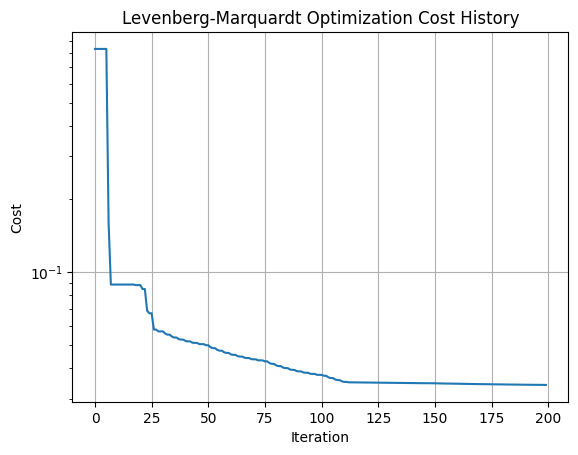

Optimized friction parameters: [ 0.05        0.1        -0.2         0.05        0.19673124  0.005     ]
Full parameter set: [ 1.5000000e+01  3.6800000e+01  5.0000000e-02  1.0000000e-01
 -2.0000000e-01  5.0000000e-02  1.9673124e-01  5.0000000e-03]
[ 1.5000000e+01  3.6800000e+01  5.0000000e-02  1.0000000e-01
 -2.0000000e-01  5.0000000e-02  1.9673124e-01  5.0000000e-03]


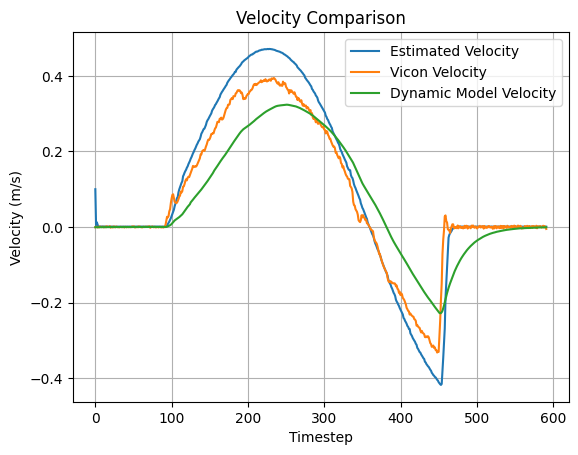

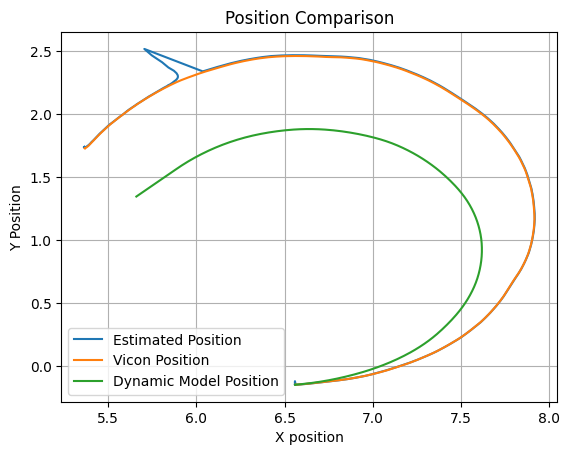

In [ ]:
import rclpy
from rclpy.node import Node
import numpy as np
import gtsam
from gtsam.symbol_shorthand import X, V, B  # Pose, Velocity, and Bias keys
import matplotlib.pyplot as plt
import math

   
class FactorGraphEstimator(Node):
    def __init__(self):
        super().__init__('factor_graph_estimator')

        # Load sensor data and downsample Vicon
        data = np.load("../Sensor_data/2025_02_20__15_45_30_arc_drive_Arclength10_ArcVel5.bag_0.npz")
        self.imu_acc = data["imu_acc"]          # (3, num_imu)
        self.imu_gyr = data["imu_gyro"]         # (3, num_imu)
        self.imu_timestamps = data["imu_timestamps"]

        self.vicon_poses = data["vicon_poses"]     # (7, num_vicon): [x, y, z, qw, qx, qy, qz]
        self.vicon_timestamps = data["vicon_timestamps"]
        x, y, z, qw, qx, qy, qz = self.vicon_poses[:, 0] # Initial pose
        self.initial_vicon_pose = gtsam.Pose3(gtsam.Rot3.Quaternion(qw, qx, qy, qz), gtsam.Point3(x, y, z))
        
        self.vicon_twists = data["vicon_twists"]
        self.vicon_twist_timestamps = data["vicon_twist_timestamps"]
        
        alpha = 0.2 # Exponential smoothing factor
        self.vicon_twists[0:3, :] = exp_mov_ave_2d(self.vicon_twists[0:3, :], alpha)
        
        

        #self.vicon_poses = self.vicon_poses[:, ::8]
        #self.vicon_timestamps = self.vicon_timestamps[::8]
        
        threshold = 5 # Setting a threshold of 5 m/sec for odometry data
        
        self.odom_twists_unfil = data["odom_twists"]
        #print(np.shape(self.odom_twists_unfil))
        self.odom_timestamps = data["odom_timestamps"]
        
        self.odom_twists = low_pass_filter(self.odom_twists_unfil, threshold) #* (0.127/0.165)
        #print(np.shape(self.odom_twists))

        print("Downsampled Vicon timestamps (first 5):", self.vicon_timestamps[:5])
        print("Downsampled Vicon poses (first 5):", self.vicon_poses[:, :5])
        
        # Setup IMU Preintegration
        params = gtsam.PreintegrationParams.MakeSharedU(9.81)
        acc_cov = np.eye(3) * (0.003**2)
        gyr_cov = np.eye(3) * (0.0035**2)
        int_cov = np.eye(3) * (0.001**2)
        params.setAccelerometerCovariance(acc_cov)
        params.setGyroscopeCovariance(gyr_cov)
        params.setIntegrationCovariance(int_cov)

        # Initially, we start with zero dynamic bias.
        self.imu_bias = gtsam.imuBias.ConstantBias(np.zeros(3), np.zeros(3))
        self.imu_preintegrator = gtsam.PreintegratedImuMeasurements(params, self.imu_bias)
        self.prev_time = None
        
        # Accumulate integration time between Vicon updates.
        self.integration_time_current = 0.0
        
        # Fixed IMU-to-Body Transform (Extrinsic Calibration)
        # (Assume identity for this example)
        self.R_imu_to_body = gtsam.Rot3()

        # Setup ISAM2 and state containers
        self.isam = gtsam.ISAM2()
        self.current_timestep = 0
        self.initialized = False
        self.new_factors = gtsam.NonlinearFactorGraph()
        self.new_values = gtsam.Values()
        self.current_odom_pose = None


        self.estimated_positions = []
        self.estimated_velocities = []
        self.estimated_biases = []
        
        self.odom_vel = []
        self.vicon_pose_processed = []
        self.vicon_twist_estimates = []
        
        self.dynamic_params = None
        
        # We'll use dt = 0.008 s for bias updates
        self.dt_bias = 0.008

        # Process sensor measurements (batch of 5 IMU then 1 Odom and 1 Vicon)
        self.process_data()

        # Plot results
        self.plot_results()
        self.estimate_and_plot_dynamic_parameters()

    def process_data(self):
        num_imu = self.imu_timestamps.shape[0]
        num_odom = self.odom_timestamps.shape[0]
        num_vicon = self.vicon_timestamps.shape[0]
        imu_idx = 0
        odom_idx = 0
        vicon_idx = 0
        imu_batch_size = 5

        while imu_idx < num_imu and odom_idx < num_odom:
            # Process a batch of 5 IMU measurements.
            for _ in range(imu_batch_size):
                if imu_idx >= num_imu:
                    break
                self.process_imu(imu_idx)
                print(f"IMU timestamp: {self.imu_timestamps[imu_idx]}")
                imu_idx += 1

            # Get the timestamp of the last IMU in the batch.
            last_imu_time = self.imu_timestamps[imu_idx - 1]
            
            while vicon_idx < num_vicon and self.vicon_timestamps[vicon_idx] < last_imu_time:
                vicon_idx += 1

            if vicon_idx < num_vicon:
                # For the very first Vicon update, pass init=True.
                init_flag = (self.current_timestep == 0)
                self.process_vicon(vicon_idx, init=init_flag)
                print(f"Vicon timestamp: {self.vicon_timestamps[vicon_idx]}")
                vicon_idx += 1
            else:
                break

            # Advance the odom index until we find one with timestamp >= last_imu_time.
            while odom_idx < num_odom and self.odom_timestamps[odom_idx] < last_imu_time:
                odom_idx += 1

            if odom_idx < num_odom:
                # For the very first odom update, pass init=True.
                init_flag = (self.current_timestep == 0)
                self.process_odom(odom_idx, init=init_flag)
                print(f"Odom timestamp: {self.odom_timestamps[odom_idx]}")
                
                odom_idx += 1
            else:
                break
        print("Finished processing sensor data.")

    def process_imu(self, idx):
        if self.prev_time is None:
            self.prev_time = self.imu_timestamps[idx]
            print(f"IMU: Initial time set at idx {idx}")
            return

        dt = self.imu_timestamps[idx] - self.prev_time
        self.prev_time = self.imu_timestamps[idx]
        self.integration_time_current += dt

        acc_imu = self.imu_acc[:, idx]
        gyro_imu = self.imu_gyr[:, idx]

        if self.current_timestep > 0:
            try:
                result = self.isam.calculateEstimate()
                estimated_pose = result.atPose3(X(self.current_timestep - 1))
            except Exception as e:
                print("Error retrieving state estimate, using identity:", e)
                estimated_pose = gtsam.Pose3()
        else:
            estimated_pose = self.initial_vicon_pose

        R_body_to_vicon = estimated_pose.rotation()
        R_imu_to_vicon = R_body_to_vicon.compose(self.R_imu_to_body)
        acc_vicon = R_imu_to_vicon.rotate(acc_imu)
        gyro_vicon = R_imu_to_vicon.rotate(gyro_imu)

        self.imu_preintegrator.integrateMeasurement(acc_vicon, gyro_vicon, dt)
        #print(f"IMU: Processed idx={idx}, dt={dt}, accumulated dt={self.integration_time_current}")

    def process_vicon(self, idx, init=False): 
        x, y, z, qw, qx, qy, qz = self.vicon_poses[:, idx]
        self.vicon_pose_processed.append(self.vicon_poses[:, idx])
        current_pose = gtsam.Pose3(gtsam.Rot3.Quaternion(qw, qx, qy, qz),
                                   gtsam.Point3(x, y, z))

        if self.current_timestep == 0 and init and not self.initialized:
            self.new_factors.add(gtsam.PriorFactorPose3(X(0), current_pose, gtsam.noiseModel.Isotropic.Sigma(6, 0.001)))
            self.new_factors.add(gtsam.PriorFactorVector(V(0), np.array([0.1, 0.1, 0]), gtsam.noiseModel.Isotropic.Sigma(3, 0.01)))
            self.new_factors.add(gtsam.PriorFactorConstantBias(B(0), self.imu_bias, gtsam.noiseModel.Isotropic.Sigma(6, 0.001)))
            if not self.new_values.exists(X(0)):
                self.new_values.insert(X(0), current_pose)
            if not self.new_values.exists(V(0)):
                self.new_values.insert(V(0), gtsam.Point3(0, 0, 0))
            if not self.new_values.exists(B(0)):
                self.new_values.insert(B(0), self.imu_bias)
            print("Initialized state at timestep 0 with Vicon pose")
        else:
            self.new_factors.add(gtsam.ImuFactor(
                X(self.current_timestep - 1), V(self.current_timestep - 1),
                X(self.current_timestep), V(self.current_timestep),
                B(self.current_timestep - 1), self.imu_preintegrator))
            zero_bias = gtsam.imuBias.ConstantBias(np.zeros(3), np.zeros(3))
            bias_sigmas = np.hstack((np.full(3, 0.003), np.full(3, 0.0035)))
            bias_noise = gtsam.noiseModel.Diagonal.Sigmas(bias_sigmas)
            self.new_factors.add(gtsam.PriorFactorPose3(X(self.current_timestep), current_pose, gtsam.noiseModel.Isotropic.Sigma(6, 0.005)))
            self.new_factors.add(gtsam.PriorFactorVector(V(self.current_timestep), np.array([0.1, 0.1, 0]), gtsam.noiseModel.Isotropic.Sigma(3, 0.01)))
            if self.current_timestep > 0:
                self.new_factors.add(gtsam.BetweenFactorConstantBias(
                    B(self.current_timestep - 1),
                    B(self.current_timestep),
                    zero_bias,
                    bias_noise))
            if not self.new_values.exists(X(self.current_timestep)):
                self.new_values.insert(X(self.current_timestep), current_pose)
            if not self.new_values.exists(V(self.current_timestep)):
                self.new_values.insert(V(self.current_timestep), self.estimated_velocities[-1])
            if not self.new_values.exists(B(self.current_timestep)):
                self.new_values.insert(B(self.current_timestep), self.imu_bias)
        self.optimize()

        
    def process_odom(self, idx, init=False):
        twist = self.odom_twists[:, idx]  # [v_x, v_y, v_z, ω_x, ω_y, ω_z]
        dt_odom = self.odom_timestamps[idx] - (self.last_odom_timestamp if hasattr(self, 'last_odom_timestamp') else self.odom_timestamps[0])
        self.last_odom_timestamp = self.odom_timestamps[idx]

        delta_rot = gtsam.Rot3.Expmap(twist[3:6] * dt_odom)
        delta_trans = twist[0:3] * dt_odom

        if init or self.current_odom_pose is None:
            self.current_odom_pose = self.initial_vicon_pose  # align odom frame to vicon at initialization
            self.heading_array = []
        else:
            self.current_odom_pose = self.current_odom_pose.compose(
                gtsam.Pose3(delta_rot, gtsam.Point3(delta_trans[0], delta_trans[1], delta_trans[2]))
            )
        # Save the twist so that later the number of odom updates and Vicon twists matches estimated velocities
        self.odom_vel.append(twist[0:3])
        
        vicon_idx = np.searchsorted(self.vicon_timestamps, self.last_odom_timestamp)
        if vicon_idx < len(self.vicon_timestamps):
            vicon_twist = self.vicon_twists[:, vicon_idx]
            x, y, z, qw, qx, qy, qz = self.vicon_poses[:, vicon_idx]
            vicon_pose = gtsam.Pose3(gtsam.Rot3.Quaternion(qw, qx, qy, qz),
                                 gtsam.Point3(x, y, z))
            heading = vicon_pose.rotation().yaw()
            self.vicon_twist_estimates.append(vicon_twist)
        else:
            self.vicon_twist_estimates.append(self.vicon_twists[:, -1])
            heading = self.heading_array[-1] if self.heading_array else 0.0
        self.heading_array.append(heading)
        
        # Applying vicon transform to odom velocities
        twist[1] = twist[0] * np.sin(heading)
        twist[0] = twist[0] * np.cos(heading)

        if self.current_timestep == 0 and init:
            initial_velocity = twist[0:3]
            self.new_factors.add(gtsam.PriorFactorPose3(
                X(0), self.current_odom_pose, gtsam.noiseModel.Isotropic.Sigma(6, 0.1)))
            self.new_factors.add(gtsam.PriorFactorVector(
                V(0), initial_velocity, gtsam.noiseModel.Isotropic.Sigma(3, 0.001)))
            self.new_factors.add(gtsam.PriorFactorConstantBias(
                B(0), self.imu_bias, gtsam.noiseModel.Isotropic.Sigma(6, 0.01)))
            if not self.new_values.exists(X(0)):
                self.new_values.insert(X(0), self.current_odom_pose)
            if not self.new_values.exists(V(0)):
                self.new_values.insert(V(0), gtsam.Point3(initial_velocity[0], initial_velocity[1], initial_velocity[2]))
            if not self.new_values.exists(B(0)):
                self.new_values.insert(B(0), self.imu_bias)
            print("Initialized state at timestep 0 with odom pose:", self.current_odom_pose)
            print("New values keys after initialization:", list(self.new_values.keys()))
        else:
            self.new_factors.add(gtsam.PriorFactorPose3(
                X(self.current_timestep), self.current_odom_pose, gtsam.noiseModel.Isotropic.Sigma(6, 0.08)))
            self.new_factors.add(gtsam.PriorFactorVector(
                V(self.current_timestep), twist[0:3], gtsam.noiseModel.Isotropic.Sigma(3, 0.001)))
            if self.current_timestep > 0:
                zero_bias = gtsam.imuBias.ConstantBias(np.zeros(3), np.zeros(3))
                bias_sigmas = np.hstack((np.full(3, 3.03e-5), np.full(3, 3.13e-4)))
                bias_noise = gtsam.noiseModel.Diagonal.Sigmas(bias_sigmas)
                self.new_factors.add(gtsam.BetweenFactorConstantBias(
                    B(self.current_timestep - 1),
                    B(self.current_timestep),
                    zero_bias,
                    bias_noise))
            if not self.new_values.exists(X(self.current_timestep)):
                self.new_values.insert(X(self.current_timestep), self.current_odom_pose)
            if not self.new_values.exists(V(self.current_timestep)):
                self.new_values.insert(V(self.current_timestep), gtsam.Point3(twist[0], twist[1], twist[2]))
            if not self.new_values.exists(B(self.current_timestep)):
                self.new_values.insert(B(self.current_timestep), self.imu_bias)
            print("Odom update at timestep", self.current_timestep, "with odom pose:", self.current_odom_pose)


    def optimize(self):
        print("Optimizing with new_values keys:", list(self.new_values.keys()))
        if self.current_timestep == 0:
            self.isam.update(self.new_factors, self.new_values)
            result = self.isam.calculateEstimate()
            self.estimated_positions.append((result.atPose3(X(0)).x(), result.atPose3(X(0)).y()))
            self.estimated_velocities.append(result.atVector(V(0)))
            self.estimated_biases.append(result.atConstantBias(B(0)))
            self.current_timestep += 1
            self.new_factors = gtsam.NonlinearFactorGraph()
            self.new_values = gtsam.Values()
            return

        try:
            self.isam.update(self.new_factors, self.new_values)
        except RuntimeError as e:
            print("ISAM2 update error:", e)
            return

        result = self.isam.calculateEstimate()
        if not result.exists(X(self.current_timestep)):
            print(f"Warning: State for timestep {self.current_timestep} does not exist.")
            return

        optimized_pose = result.atPose3(X(self.current_timestep))
        optimized_velocity = result.atVector(V(self.current_timestep))
        optimized_bias = result.atConstantBias(B(self.current_timestep))

        self.estimated_positions.append((optimized_pose.x(), optimized_pose.y()))
        self.estimated_velocities.append(optimized_velocity)
        self.estimated_biases.append(optimized_bias)
        print(f"Optimized timestep {self.current_timestep}: Pose = ({optimized_pose.x()}, {optimized_pose.y()}, {optimized_pose.z()})")
        self.current_timestep += 1
        self.new_factors = gtsam.NonlinearFactorGraph()
        self.new_values = gtsam.Values()

    def estimate_and_plot_dynamic_parameters(self):
        """
        Estimate dynamic parameters and plot the results.
        """
        # Extract relevant data for optimization.
        xs, ys = zip(*self.estimated_positions)
        xs = np.array(xs)
        ys = np.array(ys)
        vx = np.array([v[0] for v in self.estimated_velocities])
        vx_vicon = np.array([v[0] for v in self.vicon_twist_estimates])
        vy = np.array([v[1] for v in self.estimated_velocities])
        vy_vicon = np.array([v[1] for v in self.vicon_twist_estimates])
        dt = np.diff(self.odom_timestamps)
        gt_vel_x = vx_vicon  # Use Vicon velocities as ground truth.
        gt_vel_y = vy_vicon
        gt_pos_x = np.array([pose[0] for pose in self.vicon_pose_processed])
        gt_pos_y = np.array([pose[1] for pose in self.vicon_pose_processed])

        # Ensure arrays are aligned.
        vx = vx[:len(gt_vel_x)]
        vx_vicon = vx_vicon[:len(gt_vel_x)]

        # Estimate dynamic parameters.
        self.dynamic_params = estimate_dynamic_parameters(self, dt, vx, vx_vicon, vy, vy_vicon, xs, ys, gt_pos_x, gt_pos_y)

        # Plot the results.
        self.plot_dynamic_model_results()

    def plot_results(self):
        if not self.estimated_positions:
            print("No estimated positions to plot.")
            return
        
        timesteps = list(range(len(self.estimated_positions)))
        xs, ys = zip(*self.estimated_positions)
        self.xs = np.array(xs)
        self.ys = np.array(ys)
        vic_x = [pose[0] for pose in self.vicon_pose_processed]
        vic_y = [pose[1] for pose in self.vicon_pose_processed]
        self.vic_x = np.array(vic_x)
        self.vic_y = np.array(vic_y)
        
        vx = [v[0] for v in self.estimated_velocities]
        vy = [v[1] for v in self.estimated_velocities]
        vz = [v[2] for v in self.estimated_velocities]
        self.odom_vel = np.array(self.odom_vel)
        self.vicon_twist_estimates = np.array(self.vicon_twist_estimates)
        self.heading_array = np.array(self.heading_array)
        # Getting odom velocities in global frame
        vx_odom = self.odom_vel[:,0] * np.cos(self.heading_array) # Multiplying odom X- velocity with heading
        vy_odom = self.odom_vel[:,0] * np.sin(self.heading_array)
        vz_odom = self.odom_vel[:,2]
        vx_vicon = self.vicon_twist_estimates[:, 0]
        vy_vicon = self.vicon_twist_estimates[:, 1]
        vz_vicon = self.vicon_twist_estimates[:, 2]
        timesteps = list(range(len(vx)))
        
#         # Calculation of accelration from dynamic model
#         # Parameters for the dynamic model
#         m = 15 # Mass of the robot is 15kg
#         N = 15 * 9.81/4 # Normal force is assumed to be weight distributed on four wheels
#         C1 = 0.01        # Traction coefficient parameter
#         At = 0.01       # Exponential decay for traction
#         C2 = 0.005       # Linear term for traction
#         R1 = 0.005        # Roll resistance parameter 1
#         A_roll = 0.01   # Decay parameter for roll resistance
#         R2 = 0.005       # Roll resistance parameter 2
        
#         m, N, C1, At, C2, R1, A_roll, R2 = estimate_dynamic_parameters()
#         v_rel_x = vx - vx_vicon
#         f_traction_x = N * (np.sign(v_rel_x) * C1 * (1-np.exp(-At * np.abs(v_rel_x))) + C2 * v_rel_x)
#         f_roll_x = -np.sign(vx) * N * (R1*(1-np.exp(-A_roll * np.abs(vx))) + R2 * np.abs(vx))
#         F_x = 2 * f_traction_x + 4 * f_roll_x
#         acc_dyn_x = F_x/m
        
#         v_rel_y = vy - vy_vicon
#         f_traction_y = N * (np.sign(v_rel_y) * C1 * (1-np.exp(-At * np.abs(v_rel_y))) + C2 * v_rel_y)
#         f_roll_y = -np.sign(vy) * N * (R1*(1-np.exp(-A_roll * np.abs(vy))) + R2 * np.abs(vy))
#         F_y = 2 * f_traction_y + 4 * f_roll_y
#         acc_dyn_y = F_y/m
        
        # Integrate acceleration to get velocity (using dt from dt_array).
#         n = len(self.estimated_velocities)
#         vel_dyn_x = np.zeros(n)
#         pos_dyn_x = np.zeros(n)
#         vel_dyn_y = np.zeros(n)
#         pos_dyn_y = np.zeros(n)
#         for i in range(1, n):
#             vel_dyn_x[i] = vel_dyn_x[i-1] + acc_dyn_x[i] * (timesteps[i]-timesteps[i-1])
#             pos_dyn_x[i] = pos_dyn_x[i-1] + vel_dyn_x[i] * (timesteps[i]-timesteps[i-1])
#             vel_dyn_y[i] = vel_dyn_y[i-1] + acc_dyn_y[i] * (timesteps[i]-timesteps[i-1])
#             pos_dyn_y[i] = pos_dyn_y[i-1] + vel_dyn_y[i] * (timesteps[i]-timesteps[i-1])

        plt.figure()
        plt.plot(self.xs, self.ys, marker='o', linestyle='-', label='Estimated Position')
        plt.plot(self.vic_x, self.vic_y,marker='.', linestyle='-', label='Vicon Position')
        #plt.plot(pos_dyn_x, pos_dyn_y, marker = 'x', linestyle='-', label='Dynamic model Position')
        plt.xlabel('X-position (m)')
        plt.ylabel('Y-Position (m)')
        plt.title('Estimated X and Y Positions')
        plt.legend()
        plt.grid(True)
        plt.savefig("estimated_position.png")
        plt.show()

        
        #print(self.heading_array[1:100])
        #print(len(vx_odom))
        plt.figure()
        plt.plot(vx, linestyle = '-', label='v_x')
        plt.plot(vx_vicon, label='v_x_vicon')
        #plt.plot(vel_dyn_x, label='v_x_dynamic')
        plt.xlabel('Timestep')
        plt.ylabel('Velocity in X-direction (m/s)')
        plt.title('Estimated vx vs Vicon vx vs Dynamic vx')
        plt.legend()
        plt.grid(True)
        plt.savefig("estimated_vx vs vicon_vx.png")
        plt.show()
        
        plt.figure
        plt.plot(vy, label='v_y')
        plt.plot(vy_vicon, label='v_y_vicon')
        #plt.plot(vel_dyn_y, label='v_y_dynamic')
        plt.xlabel('Timestep')
        plt.ylabel('Velocity in Y-direction (m/s)')
        plt.title('Estimated vy vs Vicon vy vs Dynamic vy')
        plt.legend()
        plt.grid(True)
        plt.savefig("estimated_vy_vs_vicon_vy.png")
        plt.show()
        
        plt.figure
        plt.plot(vz_odom, label='v_z')
        plt.plot(vz_vicon, label='v_z_vicon')
        plt.xlabel('Timestep')
        plt.ylabel('Velocity in Z-direction (m/s)')
        plt.title('Estimated vz vs Vicon vz')
        plt.legend()
        plt.grid(True)
        plt.savefig("estimated_vz_vs_vicon_vz.png")
        plt.show()
        

        # Plot bias components.
        # Since estimated_biases is a list of imuBias objects, extract their values.
        gyr_biases = [b.gyroscope() for b in self.estimated_biases]
        acc_biases = [b.accelerometer() for b in self.estimated_biases]
        timesteps = list(range(len(gyr_biases)))
        
        plt.figure()
        plt.plot(timesteps, [b[0] for b in gyr_biases], label='gyr_x')
        plt.plot(timesteps, [b[1] for b in gyr_biases], label='gyr_y')
        plt.plot(timesteps, [b[2] for b in gyr_biases], label='gyr_z')
        plt.xlabel('Timestep')
        plt.ylabel('Angular velocity bias (rad/s)')
        plt.title('Estimated Gyroscope Bias Components')
        plt.legend()
        plt.grid(True)
        plt.savefig("estimated_gyr_bias_components.png")
        plt.show()
        
        plt.figure()
        plt.plot(timesteps, [b[0] for b in acc_biases], label='acc_x')
        plt.plot(timesteps, [b[1] for b in acc_biases], label='acc_y')
        plt.plot(timesteps, [b[2] for b in acc_biases], label='acc_z')
        plt.xlabel('Timestep')
        plt.ylabel('Acceleration bias (m/s^2)')
        plt.title('Estimated Acceleration Bias Components')
        plt.legend()
        plt.grid(True)
        plt.savefig("estimated_acc_bias_components.png")
        plt.show()
        
        vx_fil = self.odom_twists[0]
        vx_unfil = self.odom_twists_unfil[0]
        plt.figure()
        #plt.plot(vx_fil, marker = 'o', label='vx')
        plt.plot(vx_odom, label='vx_odom')
        #plt.plot(vy_fil, vy_unfil, label='vy')
        #plt.plot(vz_fil, vz_unfil, label='vz')
        plt.xlabel('Timesteps')
        plt.ylabel('Velocity fil vs unfil')
        plt.title('Odom vel fil vs unfil')
        plt.legend()
        plt.grid(True)
        #plt.savefig("estimated_gyr_bias_components.png")
        plt.show()
        
        
        norm_x = np.maximum(np.abs(vx), np.abs(vx_vicon))
        norm_x[norm_x == 0] = 1  # avoid division by zero
        slip_x = (vx - vx_vicon) / norm_x

        norm_y = np.maximum(np.abs(vy), np.abs(vy_vicon))
        norm_y[norm_y == 0] = 1
        slip_y = (vy - vy_vicon) / norm_y
        plt.figure()
        plt.plot(timesteps, slip_x, label = 'slip_x')
        plt.xlabel('Timesteps')
        plt.ylabel('Slip_x')
        plt.title('Slip estimate in Vicon X')
        plt.legend()
        plt.savefig("Slip_x.png")
        plt.show()
        
        plt.figure()
        plt.plot(timesteps, slip_y, label = 'slip_y')
        plt.xlabel('Timesteps')
        plt.ylabel('Slip_y')
        plt.title('Slip estimate in Vicon Y')
        plt.legend()
        plt.savefig("Slip_y.png")
        plt.show()

        
    def plot_dynamic_model_results(self):
        if self.dynamic_params is None:
            print("Dynamic parameters not yet estimated.")
            return

        # Unpack dynamic parameters.
        m, N, C1, At, C2, R1, A_roll, R2 = self.dynamic_params
        
        print(self.dynamic_params)

#         # Compute forces and integrate to get velocity/position.
        vx = np.array([v[0] for v in self.estimated_velocities])
        vx_vicon = np.array([v[0] for v in self.vicon_twist_estimates])
        vy = np.array([v[1] for v in self.estimated_velocities])
        vy_vicon = np.array([v[1] for v in self.vicon_twist_estimates])
#         dt = np.diff(self.odom_timestamps)
#         v_rel_x = vx - vx_vicon
#         f_traction_x = N * (np.sign(v_rel_x) * C1 * (1 - np.exp(-At * np.abs(v_rel_x))) + C2 * v_rel_x)
#         f_roll_x = -np.sign(vx) * N * (R1 * (1 - np.exp(-A_roll * np.abs(vx))) + R2 * np.abs(vx))
#         F_x = 2 * f_traction_x + 4 * f_roll_x
#         acc_dyn_x = F_x / m

#         vel_dyn_x = np.zeros_like(vx)
#         pos_dyn_x = np.zeros_like(vx)
#         for i in range(1, len(vx)):
#             vel_dyn_x[i] = vel_dyn_x[i - 1] + acc_dyn_x[i] * dt[i]
#             pos_dyn_x[i] = pos_dyn_x[i - 1] + vel_dyn_x[i] * dt[i]
        plt.figure()
        plt.plot(vy, label='Estimated Velocity')
        plt.plot(vy_vicon, label='Vicon Velocity')
        plt.plot(self.dynamic_model_vel_y, label='Dynamic Model Velocity')
        plt.xlabel('Timestep')
        plt.ylabel('Velocity (m/s)')
        plt.title('Velocity Comparison')
        plt.legend()
        plt.grid(True)
        plt.savefig("velocity_comparison.png")
        plt.show()

        # Plot position comparison.
        plt.figure()
        plt.plot(self.xs, self.ys, label='Estimated Position')
        plt.plot(self.vic_x, self.vic_y, label='Vicon Position')
        plt.plot(self.dynamic_model_pos_x, self.dynamic_model_pos_y, label='Dynamic Model Position')
        plt.xlabel('X position')
        plt.ylabel('Y Position')
        plt.title('Position Comparison')
        plt.legend()
        plt.grid(True)
        plt.savefig("position_comparison.png")
        plt.show()
        
def main(args=None):
    try:
        rclpy.init(args=args)
    except RuntimeError as e:
        if "Context.init() must only be called once" in str(e):
            print("rclpy context already initialized, skipping rclpy.init()")
        else:
            raise e
    node = FactorGraphEstimator()
    try:
        rclpy.spin(node)
    except KeyboardInterrupt:
        pass
    finally:
        node.destroy_node()
        rclpy.shutdown()

if __name__ == '__main__':
    main()
